# Figure 2: smoking-induced macrophages (SIMs) and PRMT7+ monocytes

Panels based on data:
- **2a** SIMs gene signature in lung macrophages and blood monocytes
- **2b** SIMs proportion in the spatial (GeoMx) data
- **2c** SIMs proportion in the lung single-cell data
- **2d** CD68 / PRMT7 immunofluorescence of lung sections of a slow and a fast progressor (raw micrographs, labels added here)
- **2e** PRMT7+ macrophages in lung sections (immunofluorescence quantification)
- **2f** proportion of PRMT7+ monocytes in the blood single-cell data
- **2g** predicted percentage of PRMT7+ monocytes in COPDGene bulk blood RNA-seq
- **2h** survival by predicted percentage of PRMT7+ monocytes in COPDGene

In [1]:
from pathlib import Path
from pprint import pprint

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import logrank_test
from scipy import stats
from scipy.cluster import hierarchy
from scipy.spatial import distance
from statsmodels.stats.multitest import multipletests

from figure_style import DENSE_FONT_SIZE, FONT_SIZE, SMALL_FONT_SIZE, figure_size, save_panel, set_style

set_style()
plt.rcParams.update({"mathtext.fontset": "custom", "mathtext.rm": "Arial", "mathtext.it": "Arial:italic", "mathtext.bf": "Arial:bold"})  # Italic p in Arial
DATA = Path("../data")

SEED = 0  # For bootstrapped confidence intervals of the bar plots

emphysema_progression_types = ["No Emphysema - Slow", "No Emphysema - Fast", "Emphysema - Slow", "Emphysema - Fast"]
emphysema_progression_colors = ["lightblue", "pink", "#4682B4", "#e31a1c"]
slow_fast_colors = emphysema_progression_colors[-2:]


def p_value_label(p_value):
    """Star notation: *** p < 0.001, ** p < 0.01, * p < 0.05, ns otherwise."""
    for threshold, stars in [(0.001, "***"), (0.01, "**"), (0.05, "*")]:
        if p_value < threshold:
            return stars
    return "ns"

## Fig. 2a: SIMs gene signature

Log fold changes (scanpy t-test, one cell type vs the rest) of the SIMs signature genes in lung macrophages and in blood monocytes.
Cell types are ordered by a dendrogram computed on their mean latent representation (scANVI for lung, PCA for blood).
Absolute log fold changes are capped at 3.

In [2]:
LOGFC_CAP = 3

sim_markers = {
    "Positive": ["FNDC3B", "LRMDA", "ZFAND3", "AKAP13", "RBM47", "ZSWIM6", "DPYD", "LPP", "PLXDC2", "ZEB2", "RASGEF1B", "KYNU", "ASAP1", "ARHGAP26", "SIK3", "PRMT7", "ANO5"],
    "Negative": ["S100A4", "FTH1", "C1QB", "HLA-DRB1", "FTL", "CST3", "TYROBP", "HLA-DRA", "S100A11", "TMSB10", "S100A6", "C1QA", "CD74", "B2M", "TMSB4X", "IGFBP2", "GPD1"],
}


def dendrogram_order(representation):
    """Hierarchical clustering of the cell types as in `scanpy.tl.dendrogram` (Pearson correlation distance, complete linkage)."""
    correlation = representation.T.corr(method="pearson")
    linkage = hierarchy.linkage(distance.squareform(1 - correlation, checks=False), method="complete")
    return linkage, hierarchy.dendrogram(linkage, labels=list(representation.index), no_plot=True)["ivl"]


def load_signature_logfc(logfc_file, representation_file):
    logfc = pd.read_csv(DATA / logfc_file, index_col=0).clip(-LOGFC_CAP, LOGFC_CAP)
    representation = pd.read_csv(DATA / representation_file, index_col=0).loc[logfc.index]
    linkage, order = dendrogram_order(representation)
    return logfc.loc[order[::-1], flatten_markers(sim_markers)], linkage


def flatten_markers(markers):
    return [gene for genes in markers.values() for gene in genes]


def plot_signature_heatmaps(datasets, name, cell_mm=3.5, label_margin_mm=33, dendrogram_mm=10, colorbar_mm=24):
    """Log fold changes of the SIMs signature genes in the lung macrophage subtypes and the blood monocyte subtypes.

    The heatmaps share the gene columns (so they are aligned) and one colour bar; the rows are ordered by the dendrograms.
    """
    genes = flatten_markers(sim_markers)
    n_rows = [len(logfc) for logfc, _ in datasets]
    heatmap_width = 183 - label_margin_mm - dendrogram_mm - colorbar_mm
    gap_mm, bracket_mm, gene_label_mm = 3, 5, 12
    height = bracket_mm + sum(n * cell_mm for n in n_rows) + gap_mm * (len(datasets) - 1) + gene_label_mm
    fig = plt.figure(figsize=figure_size(183, height))
    to_fraction = lambda x, y, w, h: [x / 183, 1 - (y + h) / height, w / 183, h / height]  # mm (from the top left) -> figure fraction

    y = bracket_mm
    for i, (logfc, linkage) in enumerate(datasets):
        h = len(logfc) * cell_mm
        ax = fig.add_axes(to_fraction(label_margin_mm, y, heatmap_width, h))
        mesh = ax.pcolormesh(logfc.values[::-1], cmap="bwr", vmin=-LOGFC_CAP, vmax=LOGFC_CAP, edgecolors="lightgray", linewidth=0.2)
        ax.set_yticks(np.arange(len(logfc)) + 0.5, logfc.index[::-1], fontsize=SMALL_FONT_SIZE)
        ax.set_xticks(np.arange(len(genes)) + 0.5, genes if i == len(datasets) - 1 else [], rotation=90, fontsize=DENSE_FONT_SIZE)
        ax.tick_params(length=0, pad=1)
        for spine in ax.spines.values():
            spine.set_linewidth(0.5)

        # Dendrogram of the cell types, leaves aligned with the rows
        ax_dendrogram = fig.add_axes(to_fraction(label_margin_mm + heatmap_width + 1, y, dendrogram_mm - 1, h))
        with plt.rc_context({"lines.linewidth": 0.5}):
            hierarchy.dendrogram(linkage, orientation="right", ax=ax_dendrogram, color_threshold=0, above_threshold_color="black", no_labels=True)
        ax_dendrogram.axis("off")

        if i == 0:  # Gene groups of the signature, above the first heatmap
            ax_groups = fig.add_axes(to_fraction(label_margin_mm, 0, heatmap_width, bracket_mm), sharex=ax)
            ax_groups.axis("off")
            x = 0
            for group, group_genes in sim_markers.items():
                ax_groups.plot([x + 0.1, x + len(group_genes) - 0.1], [0.15, 0.15], color="black", lw=0.5, clip_on=False)
                ax_groups.text(x + len(group_genes) / 2, 0.4, group, ha="center", va="bottom", fontsize=FONT_SIZE)
                x += len(group_genes)
            ax_groups.set_ylim(0, 1)
        y += h + gap_mm

    ax_colorbar = fig.add_axes(to_fraction(183 - colorbar_mm + 8, bracket_mm + 2, colorbar_mm - 12, 2.5))
    colorbar = fig.colorbar(mesh, cax=ax_colorbar, orientation="horizontal", ticks=[-LOGFC_CAP, 0, LOGFC_CAP])
    colorbar.ax.set_title("log fold change", fontsize=FONT_SIZE, pad=2)
    colorbar.ax.tick_params(labelsize=SMALL_FONT_SIZE, length=2, width=0.5)
    colorbar.outline.set_linewidth(0.5)
    save_panel(name)
    plt.show()

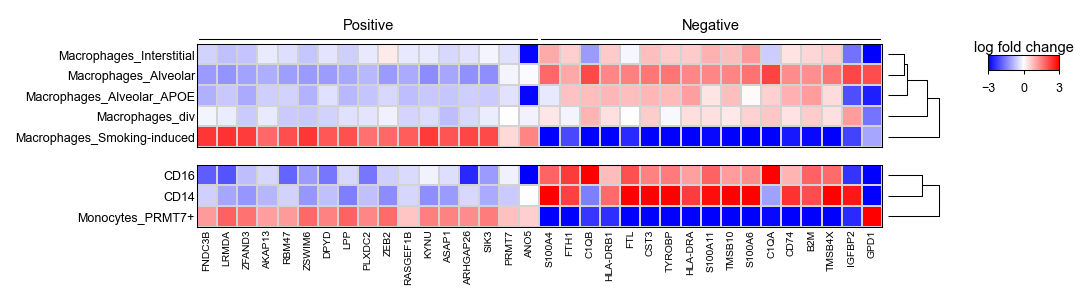

In [3]:
plot_signature_heatmaps(
    [
        load_signature_logfc("lung_macrophages_SIMs_signature_logFC.csv", "lung_macrophages_scanvi_mean.csv"),
        load_signature_logfc("blood_monocytes_SIMs_signature_logFC.csv", "blood_monocytes_pca_mean.csv"),
    ],
    "Fig_2_a_SIMs_signature",
)

## Fig. 2b: SIMs proportion in the spatial data

Cell type deconvolution of GeoMx regions of interest. Fast vs slow progressors are compared within each region and emphysema status with Welch's t-test, Benjamini-Hochberg corrected.

In [4]:
deconvolution_df = pd.read_csv(DATA / "2_GeoMx_deconvolution_proportions.csv")
regions_order = ["Airway", "Lymphoid follicle", "Parenchyma", "Vessel"]
deconvolution_df.shape

(881, 19)

In [5]:
fast_progressors = deconvolution_df[deconvolution_df["Fast"] == 1]
slow_progressors = deconvolution_df[deconvolution_df["Fast"] == 0]

spatial_pvalues = {}
for region in regions_order:
    for emphysema_status in [0, 1]:
        group = "control" if emphysema_status == 0 else "emphysema"
        spatial_pvalues[f"{region} – {group}"] = stats.ttest_ind(
            fast_progressors.loc[(fast_progressors["region"] == region) & (fast_progressors["Emphysema"] == emphysema_status), "Macrophages_Smoking-induced"],
            slow_progressors.loc[(slow_progressors["region"] == region) & (slow_progressors["Emphysema"] == emphysema_status), "Macrophages_Smoking-induced"],
            equal_var=False,
        ).pvalue

spatial_pvalues_adjusted = dict(zip(spatial_pvalues, multipletests(list(spatial_pvalues.values()), method="fdr_bh")[1]))
pprint(spatial_pvalues_adjusted)

{'Airway – control': 0.5477791187747999,
 'Airway – emphysema': 0.026561430763507414,
 'Lymphoid follicle – control': 0.07392890220708215,
 'Lymphoid follicle – emphysema': 0.026561430763507414,
 'Parenchyma – control': 0.13059957654080045,
 'Parenchyma – emphysema': 0.00018961356845464202,
 'Vessel – control': 0.021720700184799196,
 'Vessel – emphysema': 0.006831736725088413}


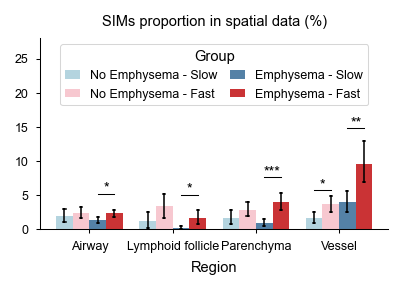

In [6]:
plt.figure(figsize=figure_size(76, 42))
plt.grid(False)
sns.barplot(
    deconvolution_df, x="region", y="Macrophages_Smoking-induced", hue="Emphysema Progression Type",
    hue_order=emphysema_progression_types, palette=emphysema_progression_colors, order=regions_order,
    capsize=0.1, err_kws={"color": "black", "linewidth": 0.75}, seed=SEED,
)
plt.legend(title="Group", loc="upper center", ncol=2, columnspacing=1, handlelength=1.2)  # Above the bars and the p-value labels
plt.ylim(0, 28)
plt.title("SIMs proportion in spatial data (%)")
plt.ylabel("")
plt.xlabel("Region")
sns.despine(top=True, right=True)

y_offset = 1  # Percentage points between the confidence interval and the p-value label
for i, region in enumerate(regions_order):
    for emphysema_status in [0, 1]:
        group = "control" if emphysema_status == 0 else "emphysema"
        p_val = spatial_pvalues_adjusted[f"{region} – {group}"]
        if p_val >= 0.05:
            continue
        fast_data = fast_progressors[(fast_progressors["region"] == region) & (fast_progressors["Emphysema"] == emphysema_status)]["Macrophages_Smoking-induced"]
        slow_data = slow_progressors[(slow_progressors["region"] == region) & (slow_progressors["Emphysema"] == emphysema_status)]["Macrophages_Smoking-induced"]
        # Place the label above the upper end of the 95% confidence intervals of the two bars
        y_max_bars = max(fast_data.mean() + 1.96 * stats.sem(fast_data), slow_data.mean() + 1.96 * stats.sem(slow_data))
        x_pos = i - 0.2 if emphysema_status == 0 else i + 0.2
        y_label = y_max_bars + y_offset * (1 if emphysema_status == 0 else 2.5)  # Stagger labels of neighbouring groups
        plt.text(x_pos, y_label, p_value_label(p_val), horizontalalignment="center", fontsize=FONT_SIZE)
        plt.plot([x_pos - 0.1, x_pos + 0.1], [y_label - y_offset * 0.2] * 2, color="black", linewidth=0.5)

save_panel("Fig_2_b_SIMs_spatial")
plt.show()

## Fig. 2c: SIMs proportion in the lung single-cell data

Proportion of SIMs among immune cells per sample. Samples with fewer than 750 cells and samples without CT-based progression status are excluded.
Current and former smokers of each progression group are compared with never smokers (Welch's t-test, Benjamini-Hochberg corrected).

In [7]:
immune_props = pd.read_csv(DATA / "3_lung_immune_cell_type_proportions.csv", index_col=0)
immune_props = immune_props[(immune_props["n_cells"] >= 750) & (immune_props["Emphysema Progression"] != "Unknown")]
immune_props.shape


def compare_with_never_smokers(props, cell_type):
    """Compare proportions of a cell type in current / former smokers of each progression group with never smokers."""
    controls = props[props["Smoking Status"] == "never"]
    pvalues = {}
    for smoking_status in ["current", "former"]:
        for progression_type in ["fast", "slow"]:
            subset = props[(props["Emphysema Progression"] == progression_type) & (props["Smoking Status"] == smoking_status)]
            pvalues[f"{progression_type}: {smoking_status} vs never"] = stats.ttest_ind(subset[cell_type], controls[cell_type], equal_var=False).pvalue
    return dict(zip(pvalues, multipletests(list(pvalues.values()), method="fdr_bh")[1]))


def plot_proportion_by_smoking_status(props, cell_type, title, pvalues_adjusted=None, errorbar=("ci", 95), y_offset=10):
    plt.figure(figsize=figure_size(46, 42))
    sns.barplot(
        data=props, y=cell_type, x="Smoking Status", hue="Emphysema Progression",
        order=["never", "current", "former"], hue_order=["slow", "fast"], palette=slow_fast_colors,
        errorbar=errorbar, capsize=0.1, err_kws={"color": "black", "linewidth": 0.75}, seed=SEED,
    )
    sns.swarmplot(
        data=props, y=cell_type, x="Smoking Status", hue="Emphysema Progression",
        order=["never", "current", "former"], hue_order=["slow", "fast"], dodge=True, legend=None, color="black", size=1.5,
    )
    plt.ylabel("")
    plt.legend(loc="upper center", ncol=2, title="Emphysema progression", frameon=False, columnspacing=1, handlelength=1.2)
    plt.title(title)
    sns.despine(top=True, right=True)

    if pvalues_adjusted is not None:
        for i, smoking_status in enumerate(["current", "former"], start=1):
            for progression_type in ["slow", "fast"]:
                p_val = pvalues_adjusted[f"{progression_type}: {smoking_status} vs never"]
                if p_val >= 0.1:
                    continue
                y_max_bars = props[(props["Smoking Status"] == smoking_status) & (props["Emphysema Progression"] == progression_type)][cell_type].mean()
                x_start, x_end = 0, i - 0.2 if progression_type == "slow" else i + 0.2
                plt.text((x_end + x_start) / 2, y_max_bars + y_offset, p_value_label(p_val), horizontalalignment="center", fontsize=FONT_SIZE)
                plt.plot([x_start, x_end], [y_max_bars + y_offset * 0.93] * 2, color="black", linewidth=0.5)

    plt.ylim(0, props[cell_type].max() * 1.4)  # Room for the legend above the points; error bars can shift the lower limit below 0
    plt.grid(False)

In [8]:
sims_pvalues_adjusted = compare_with_never_smokers(immune_props, "Macrophages_Smoking-induced")
pprint(sims_pvalues_adjusted)

{'fast: current vs never': 0.028609222109843693,
 'fast: former vs never': 0.34704433389479106,
 'slow: current vs never': 0.7639558717714532,
 'slow: former vs never': 0.3997617071959268}


/var/folders/tc/fk7_q9y91qq3phd1l5xxg7_h0000gn/T/ipykernel_80424/3346263850.py:24: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.swarmplot(


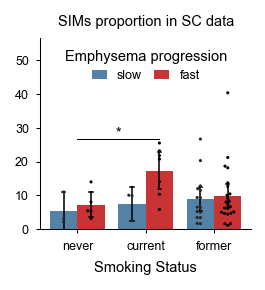

In [9]:
plot_proportion_by_smoking_status(
    immune_props, "Macrophages_Smoking-induced", title="SIMs proportion in SC data",
    pvalues_adjusted=sims_pvalues_adjusted, errorbar=("se", 2),  # 2 standard errors, i.e. approximately 95% confidence interval
)
save_panel("Fig_2_c_SIMs_proportion_SC")
plt.show()

## Fig. 2d: CD68 / PRMT7 immunofluorescence of lung sections

Raw micrographs (CD68 red, PRMT7 green, nuclei blue) of a slow and a fast progressor among current smokers without emphysema,
extracted from the slide `SIMs_fluorescence_validation/PRMT7 Mac raw data.pptx` (see the README). The slide shows every image at the
same size with one 20 µm scale bar on the slow CD68 image, and a zoomed region of the fast merged image; both are reproduced here
from the geometry of that slide. The panel is laid out with the two sections as columns so that it fits next to Fig. 2e.

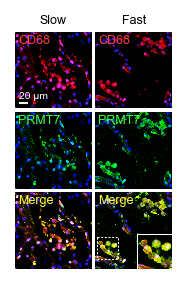

In [10]:
RAW_IMAGES = DATA / "SIMs_fluorescence_validation" / "raw_images"
CHANNELS = [("CD68", "#ff4040"), ("PRMT7", "#40ff40"), ("Merge", "#ffff40")]  # Label colours as in the original slide
SCALE_BAR_FRACTION = 5.6 / 45.5  # 20 µm scale bar: 5.6 mm on a 45.5 mm wide image on the original slide
INSET_REGION = (0.0175, 0.586, 0.30, 0.867)  # Zoomed region of the fast merged image (left, top, right, bottom as fractions), from the slide
INSET_ZOOM = 1.6  # Size of the inset relative to the region it magnifies


def plot_immunofluorescence(width_mm=27, image_mm=13, gap_mm=0.6, header_mm=3):
    height_mm = header_mm + 3 * image_mm + 2 * gap_mm
    fig = plt.figure(figsize=figure_size(width_mm, height_mm))
    to_fraction = lambda x, y, w, h: [x / width_mm, 1 - (y + h) / height_mm, w / width_mm, h / height_mm]  # mm from the top left
    for column, section in enumerate(["slow", "fast"]):
        x = column * (image_mm + gap_mm)
        fig.text((x + image_mm / 2) / width_mm, 1 - (header_mm - 0.8) / height_mm, section.capitalize(), ha="center", va="bottom", fontsize=SMALL_FONT_SIZE)
        for row, (channel, color) in enumerate(CHANNELS):
            y = header_mm + row * (image_mm + gap_mm)
            ax = fig.add_axes(to_fraction(x, y, image_mm, image_mm))
            image = plt.imread(RAW_IMAGES / f"{section}_{channel.lower()}.png")
            ax.imshow(image, interpolation="none")
            ax.set_axis_off()
            ax.text(0.04, 0.96, channel, color=color, fontsize=SMALL_FONT_SIZE, ha="left", va="top", transform=ax.transAxes)
            n = image.shape[1]
            if section == "slow" and channel == "CD68":  # Scale bar as on the original slide
                ax.plot([0.05 * n, (0.05 + SCALE_BAR_FRACTION) * n], [0.93 * n] * 2, color="white", linewidth=1, solid_capstyle="butt")
                ax.text(0.05 * n, 0.90 * n, "20 µm", color="white", fontsize=DENSE_FONT_SIZE, ha="left", va="bottom")
            if section == "fast" and channel == "Merge":  # Magnified region in the lower right corner
                left, top, right, bottom = INSET_REGION
                ax.add_patch(plt.Rectangle((left * n, top * n), (right - left) * n, (bottom - top) * n, fill=False, edgecolor="white", linewidth=0.5, linestyle=(0, (2, 1.5))))
                inset_mm = (right - left) * image_mm * INSET_ZOOM
                inset_ax = fig.add_axes(to_fraction(x + image_mm - inset_mm, y + image_mm - inset_mm, inset_mm, inset_mm))
                inset_ax.imshow(plt.imread(RAW_IMAGES / "fast_merge_inset.png"), interpolation="none")
                inset_ax.set_xticks([])
                inset_ax.set_yticks([])
                for spine in inset_ax.spines.values():
                    spine.set_edgecolor("white")
                    spine.set_linewidth(0.5)
    return fig


plot_immunofluorescence()
save_panel("Fig_2_d_PRMT7_immunofluorescence", png_dpi=600, tight=False)
plt.show()

## Fig. 2e: PRMT7+ macrophages in lung sections (immunofluorescence)

CD68 / PRMT7 co-staining of lung sections of current smokers without emphysema. For each slide, the percentage of PRMT7+ cells among
CD68+ macrophages is compared between fast and slow progressors with Welch's t-test (one comparison, no correction).
The sample with a single counted macrophage (UA 41) is kept, as in the original quantification.

In [11]:
fluorescence = pd.read_excel(DATA / "SIMs_fluorescence_validation" / "Raw data for PRMT7 XW updated.xlsx", usecols=range(5))
fluorescence.columns = ["slide", "group", "PRMT7+ macrophages", "total macrophages", "fraction"]
fluorescence["Emphysema progression"] = fluorescence["group"].str.extract(r"(slow|fast)")[0].str.capitalize()
fluorescence["PRMT7+ macrophages (%)"] = 100 * fluorescence["fraction"]
fluorescence.groupby("Emphysema progression")["PRMT7+ macrophages (%)"].agg(["count", "mean", "std"]).round(1)

,count,mean,std
Emphysema progression,,,
Fast,5,88.7,9.2
Slow,4,62.4,9.4


In [12]:
slow_fraction = fluorescence.loc[fluorescence["Emphysema progression"] == "Slow", "PRMT7+ macrophages (%)"]
fast_fraction = fluorescence.loc[fluorescence["Emphysema progression"] == "Fast", "PRMT7+ macrophages (%)"]
fluorescence_test = stats.ttest_ind(fast_fraction, slow_fraction, equal_var=False)
print(f"slow n = {len(slow_fraction)}, fast n = {len(fast_fraction)}, Welch's t-test p = {fluorescence_test.pvalue:.2g}")

slow n = 4, fast n = 5, Welch's t-test p = 0.0046


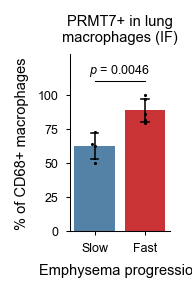

In [13]:
# Narrow panel: the axes are placed at a fixed position and the canvas is saved uncropped, so the labels cannot widen it
width_mm, height_mm = 32, 50
fig = plt.figure(figsize=figure_size(width_mm, height_mm))
ax = fig.add_axes([9.5 / width_mm, 11 / height_mm, 17 / width_mm, 30 / height_mm])
sns.barplot(
    fluorescence, x="Emphysema progression", y="PRMT7+ macrophages (%)", hue="Emphysema progression", order=["Slow", "Fast"], hue_order=["Slow", "Fast"],
    palette=slow_fast_colors, legend=False, errorbar=("se", 2), capsize=0.15, err_kws={"color": "black", "linewidth": 0.75}, seed=SEED, ax=ax,
)
sns.swarmplot(fluorescence, x="Emphysema progression", y="PRMT7+ macrophages (%)", order=["Slow", "Fast"], color="black", size=1.5, ax=ax)
ax.set_title("PRMT7+ in lung\nmacrophages (IF)")
y_bracket = 110
ax.plot([0, 1], [y_bracket, y_bracket], color="black", linewidth=0.5)
ax.text(0.5, y_bracket + 2, f"$p$ = {fluorescence_test.pvalue:.2g}", ha="center", va="bottom", fontsize=SMALL_FONT_SIZE)
ax.set_ylim(0, 130)
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_ylabel("% of CD68+ macrophages")
ax.set_xlabel("Emphysema progression")
sns.despine(ax=ax, top=True, right=True)
ax.grid(False)
save_panel("Fig_2_e_PRMT7_macrophages_IF", tight=False)
plt.show()

## Fig. 2f: proportion of PRMT7+ monocytes in the blood single-cell data

Proportion of PRMT7+ monocytes among all cells per sample. Samples with fewer than 750 cells and samples without CT-based progression status are excluded.

In [14]:
cell_props = pd.read_csv(DATA / "4_blood_cell_type_proportions.csv", index_col=0)
cell_props = cell_props[(cell_props["n_cells"] >= 750) & (cell_props["Emphysema Progression"] != "Unknown")]
cell_props.shape

(42, 26)

In [15]:
pprint(compare_with_never_smokers(cell_props, "Monocytes_PRMT7+"))

{'fast: current vs never': 0.5533295376896922,
 'fast: former vs never': 0.2891569234967826,
 'slow: current vs never': 0.7032158855954426,
 'slow: former vs never': 0.5533295376896922}


/var/folders/tc/fk7_q9y91qq3phd1l5xxg7_h0000gn/T/ipykernel_80424/3346263850.py:24: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.swarmplot(


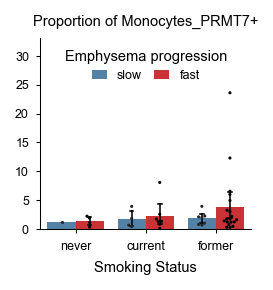

In [16]:
plot_proportion_by_smoking_status(cell_props, "Monocytes_PRMT7+", title="Proportion of Monocytes_PRMT7+")
save_panel("Fig_2_f_PRMT7_monocytes_proportion")
plt.show()

## Fig. 2g: predicted percentage of PRMT7+ monocytes in COPDGene bulk blood RNA-seq

The fraction of PRMT7+ monocytes was predicted with InstaPrism deconvolution. Its association with emphysema progression is tested
with a linear mixed model adjusted for lung density, sex, smoking status and age, with sequencing batch as a random effect.
The bar plot shows all samples, the model excludes samples with missing percent emphysema, as in the original analysis.

In [17]:
bulk = pd.read_csv(DATA / "5_bulk_COPDGene_PRMT7_monocytes.csv", index_col=0)
bulk["Monocytes_PRMT7+ (%)"] = bulk["Monocytes_PRMT7+"] * 100
bulk.shape

(999, 11)

In [18]:
df_model = bulk.dropna(subset=["pctEmph"]).copy()  # Percent emphysema was among the model variables in the original analysis, samples with missing values were dropped
df_model["SIMs_like_fraction"] = df_model["Monocytes_PRMT7+"]  # Formula doesn't allow "+" in column names
for feature in ["age_visit", "lung_density_vnb"]:
    df_model[feature] = (df_model[feature] - df_model[feature].mean()) / df_model[feature].std()
df_model["LcBatch"] = df_model["LcBatch"].astype("category")

model = smf.mixedlm(
    "SIMs_like_fraction ~ lung_density_vnb + C(gender) + emphysema_progression + C(smoking_status) + age_visit",
    data=df_model,
    groups=df_model["LcBatch"],
    re_formula="~1",
)
result = model.fit()
result.summary()

/Users/vladimir.shitov/miniconda3/envs/2023_12_COPD/lib/python3.11/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


<class 'statsmodels.iolib.summary2.Summary'>
"""
               Mixed Linear Model Regression Results
===================================================================
Model:             MixedLM  Dependent Variable:  SIMs_like_fraction
No. Observations:  997      Method:              REML              
No. Groups:        53       Scale:               0.0035            
Min. group size:   3        Log-Likelihood:      1315.9983         
Max. group size:   33       Converged:           Yes               
Mean group size:   18.8                                            
-------------------------------------------------------------------
                         Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------
Intercept                 0.094    0.011  8.593 0.000  0.073  0.116
C(gender)[T.2]            0.005    0.004  1.351 0.177 -0.002  0.013
C(smoking_status)[T.1.0]  0.004    0.009  0.405 0.686 -0.015  0.022
C(smoking_status)[T.2.0]  0.004    0.010  0.431 0.666 -0.015  0.023
lung_density_vnb         -0.003    0.002 -1.428 0.153 -0.007  0.001
emphysema_progression     0.007    0.004  1.718 0.086 -0.001  0.014
age_visit                 0.006    0.002  2.702 0.007  0.002  0.010
Group Var                 0.002    0.006                           
===================================================================

"""

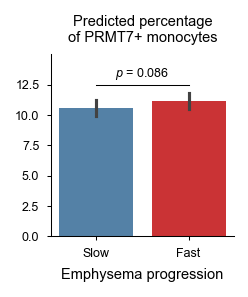

In [19]:
plt.figure(figsize=figure_size(40, 40))
sns.barplot(bulk, x="emphysema_progression", y="Monocytes_PRMT7+ (%)", hue="emphysema_progression", palette=slow_fast_colors, legend=False, seed=SEED)
plt.title("Predicted percentage\nof PRMT7+ monocytes")
# Comparison of the two groups (mixed model) above the bars
y_bracket = bulk.groupby("emphysema_progression")["Monocytes_PRMT7+ (%)"].mean().max() * 1.12
plt.plot([0, 1], [y_bracket, y_bracket], color="black", linewidth=0.5)
plt.text(0.5, y_bracket * 1.02, f"$p$ = {result.pvalues['emphysema_progression']:.2g}", ha="center", va="bottom", fontsize=SMALL_FONT_SIZE)
plt.ylim(0, y_bracket * 1.2)
sns.despine(top=True, right=True)
plt.xlabel("Emphysema progression")
plt.ylabel("")
plt.xticks(ticks=[0, 1], labels=["Slow", "Fast"])
save_panel("Fig_2_g_PRMT7_monocytes_bulk")
plt.show()

## Fig. 2h: survival by predicted percentage of PRMT7+ monocytes

Kaplan-Meier curves for the lowest and highest quartiles of the predicted percentage of PRMT7+ monocytes, compared with the log-rank test.

In [20]:
def plot_km_by_quartile(df, split_var, group_names=("Low", "High"), duration_col="days_followed_since_phase_2", event_col="vital_status"):
    low_name, high_name = group_names
    surv_df = df[[duration_col, event_col, split_var]].dropna().copy()

    q1, q3 = surv_df[split_var].quantile([0.25, 0.75])
    surv_df["patient_group"] = pd.cut(surv_df[split_var], bins=[-np.inf, q1, q3, np.inf], labels=[low_name, "Medium", high_name])
    low = surv_df[surv_df["patient_group"] == low_name]
    high = surv_df[surv_df["patient_group"] == high_name]

    results = logrank_test(low[duration_col], high[duration_col], event_observed_A=low[event_col], event_observed_B=high[event_col])
    results.print_summary()
    print("Group sizes:", {low_name: len(low), high_name: len(high)})

    fig = plt.figure(figsize=figure_size(72, 46))
    ax = fig.add_axes([0.16, 0.54, 0.8, 0.34])  # Leave the lower part of the panel to the x-axis label and the at-risk table
    kmf_low = KaplanMeierFitter().fit(low[duration_col], event_observed=low[event_col], label=low_name)
    kmf_low.plot(ax=ax, ci_show=True, color="#4682B4")
    kmf_high = KaplanMeierFitter().fit(high[duration_col], event_observed=high[event_col], label=high_name)
    kmf_high.plot(ax=ax, ci_show=True, color="#e31a1c")

    ax.set_xlabel("Days Followed since Phase 2")
    ax.set_title(f"Kaplan-Meier survival curve by\n{split_var}")
    ax.set_ylabel("Survival Probability")
    ax.legend(loc="lower left", title=f"log-rank test: {p_value_label(results.p_value)}")
    sns.despine(ax=ax, top=True, right=True)
    add_at_risk_counts(kmf_low, kmf_high, ax=ax, ypos=-0.2, fontsize=SMALL_FONT_SIZE)
    return results

<lifelines.StatisticalResult: logrank_test>
               t_0 = -1
 null_distribution = chi squared
degrees_of_freedom = 1
         test_name = logrank_test

---
 test_statistic    p  -log2(p)
           2.21 0.14      2.87

Group sizes: {'Low': 250, 'High': 250}


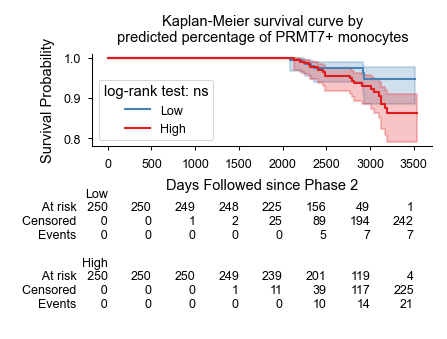

In [21]:
survival_df = bulk.rename(columns={"Monocytes_PRMT7+ (%)": "predicted percentage of PRMT7+ monocytes"})
plot_km_by_quartile(survival_df, "predicted percentage of PRMT7+ monocytes")
save_panel("Fig_2_h_PRMT7_monocytes_survival")
plt.show()